In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

Saving Ata Turk.jpg to Ata Turk.jpg


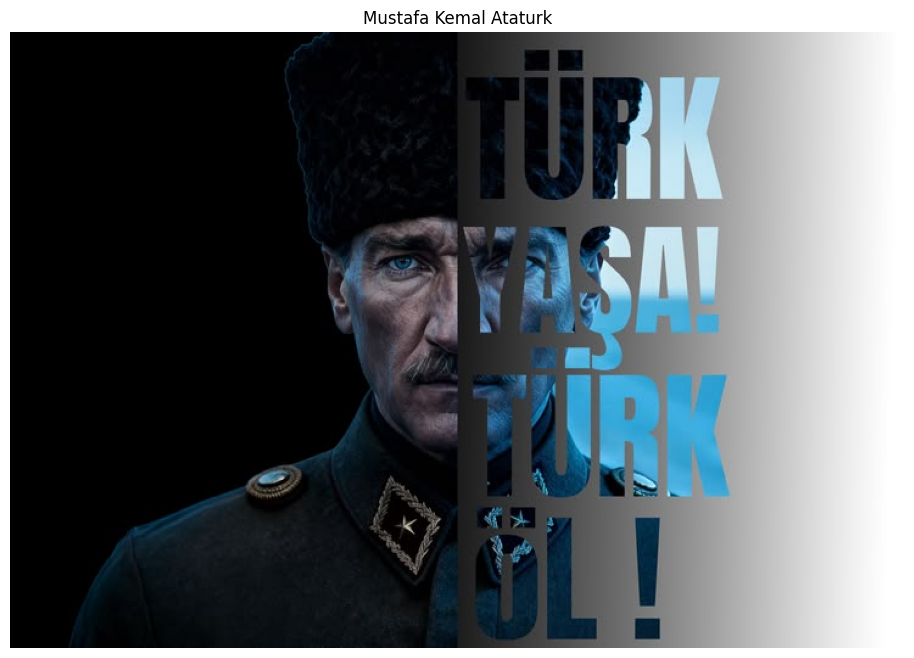

In [2]:
uploaded = files.upload()

if len(uploaded) == 0:
  raise ValueError("No File Uploaded")

image_name = list(uploaded.keys())[0]
image_path = '/content/' + image_name

img = cv2.imread(image_path)

if img is None:
  raise ValueError("Invalid Image")

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Mustafa Kemal Ataturk')

plt.axis('off')
plt.show()

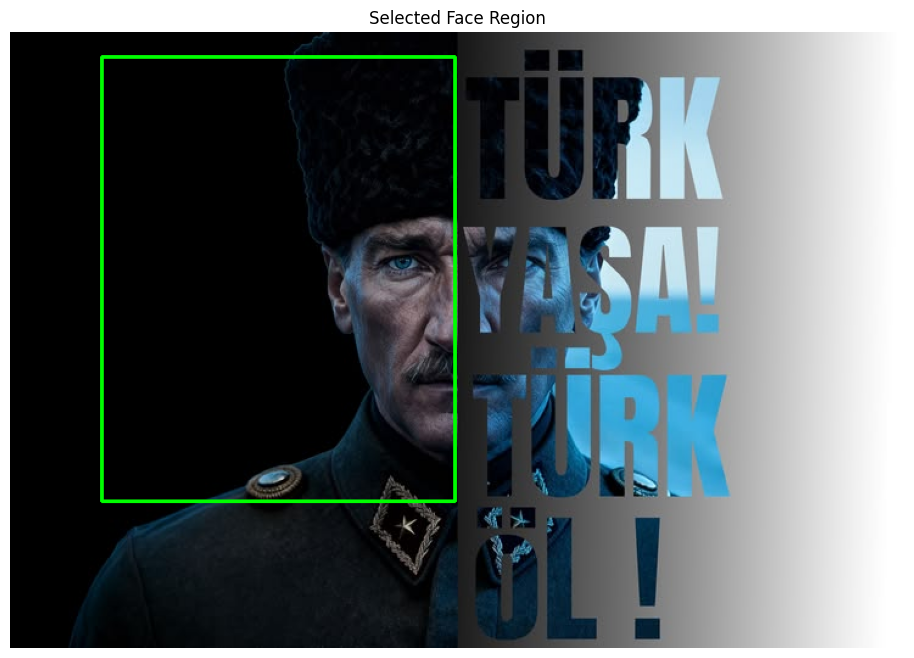

Face region: x1=75, y1=20, x2=365, y2=385
Region size: width=290, height=365


In [3]:
x1 = 75
y1 = 20
x2 = 365
y2 = 385

img_with_rect = img.copy()
cv2.rectangle(img_with_rect, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(12, 8))

plt.imshow(cv2.cvtColor(img_with_rect, cv2.COLOR_BGR2RGB))
plt.title('Selected Face Region')

plt.axis('off')
plt.show()

print(f"Face region: x1={x1}, y1={y1}, x2={x2}, y2={y2}")
print(f"Region size: width={x2-x1}, height={y2-y1}")

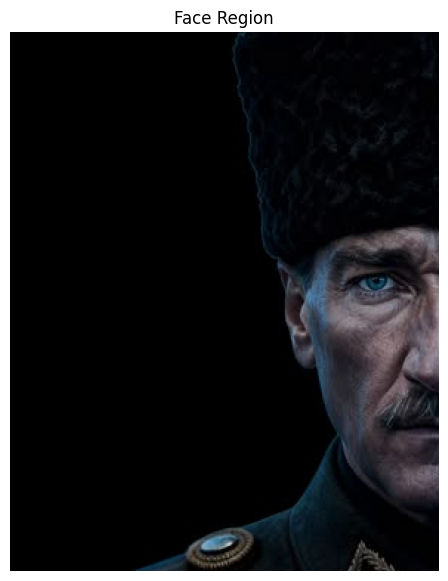

In [4]:
face_region = img[y1:y2, x1:x2].copy()

plt.figure(figsize=(6, 7))

plt.imshow(cv2.cvtColor(face_region, cv2.COLOR_BGR2RGB))
plt.title('Face Region')
plt.axis('off')

plt.show()

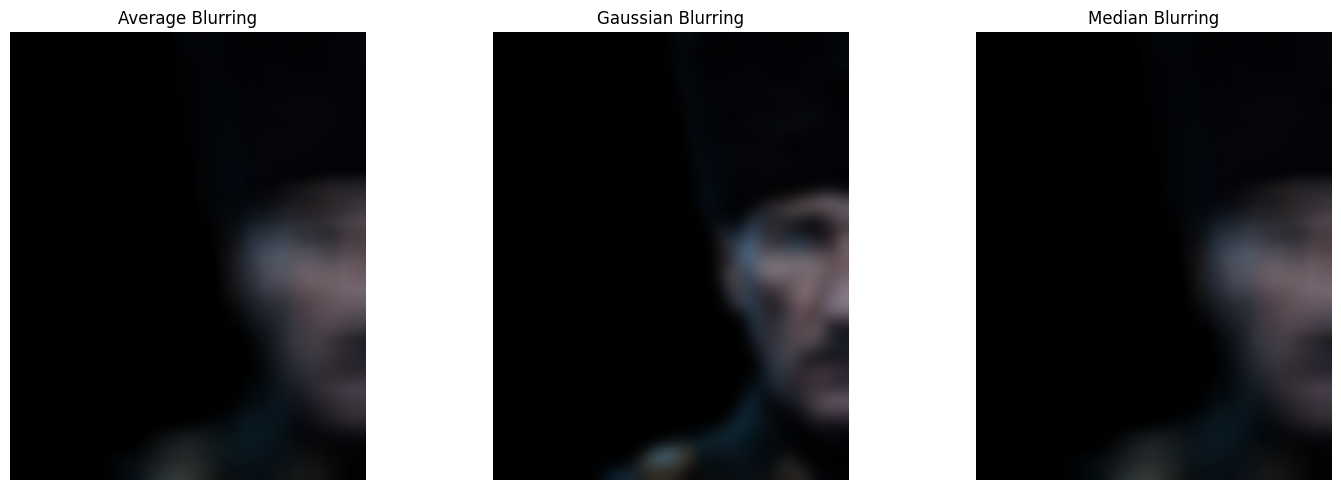

In [5]:
blurred_avg = cv2.blur(face_region, (41, 41))

blurred_gaussian = cv2.GaussianBlur(face_region, (41, 41), 0)

kernel_size  = 41
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
blurred_median = cv2.filter2D(face_region, -1, kernel)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(blurred_avg, cv2.COLOR_BGR2RGB))
plt.title('Average Blurring')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(blurred_gaussian, cv2.COLOR_BGR2RGB))
plt.title('Gaussian Blurring')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(blurred_median, cv2.COLOR_BGR2RGB))
plt.title('Median Blurring')
plt.axis('off')

plt.tight_layout()
plt.show()

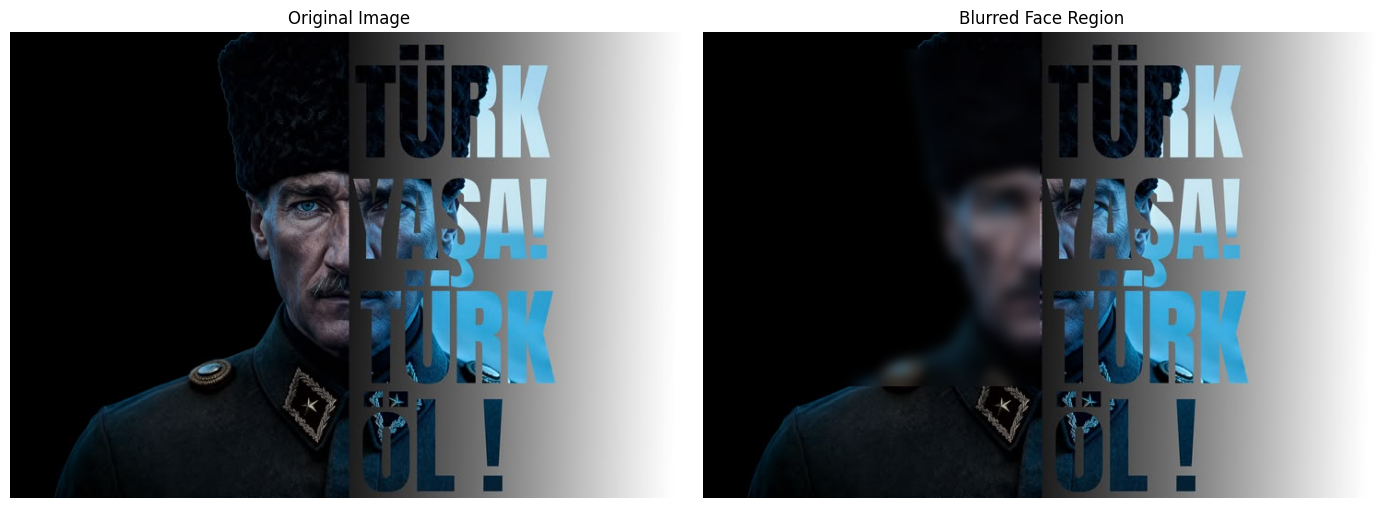

In [8]:
blurred_face = blurred_gaussian

result = img.copy()
result[y1:y2, x1:x2] = blurred_face

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Blurred Face Region')
plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
cv2.imwrite('result.jpg', result)
print('Result Saved "result.jpg"')

files.download('result.jpg')
print('Downloaded: "result.jpg"')

Result Saved "result.jpg"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: "result.jpg"
